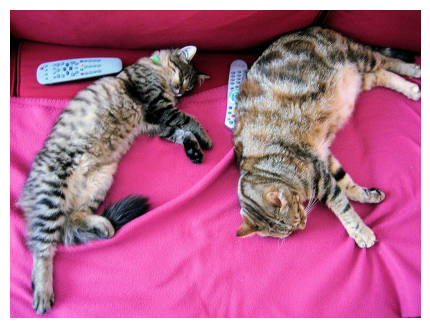

In [27]:
import tensorflow as tf
import matplotlib.pyplot as plt

img = tf.io.read_file('cat.jpg')
img_decoded = tf.image.decode_jpeg(img, channels=3)    

img_decoded_disp = tf.cast(img_decoded, tf.float32) / 255.0

plt.figure(figsize=(8,4))
plt.imshow(img_decoded_disp.numpy())
plt.axis('off')
plt.show()


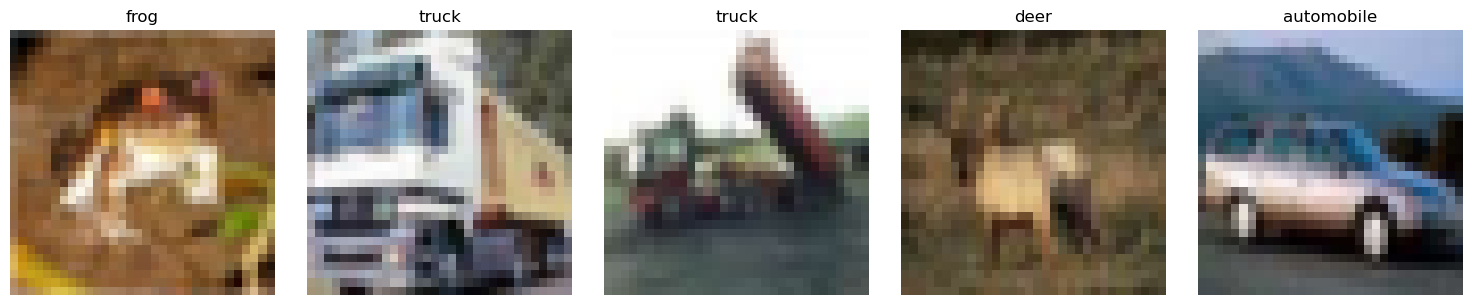

In [22]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

num_images = 5  

plt.figure(figsize=(15, 3))
for i in range(num_images):
    img = X_train[i]
    label = y_train[i][0]
    plt.subplot(1, num_images, i + 1)
    plt.imshow(img)
    plt.title(class_names[label])
    plt.axis('off')
    
plt.tight_layout()
plt.show()


Found 4 files belonging to 2 classes.


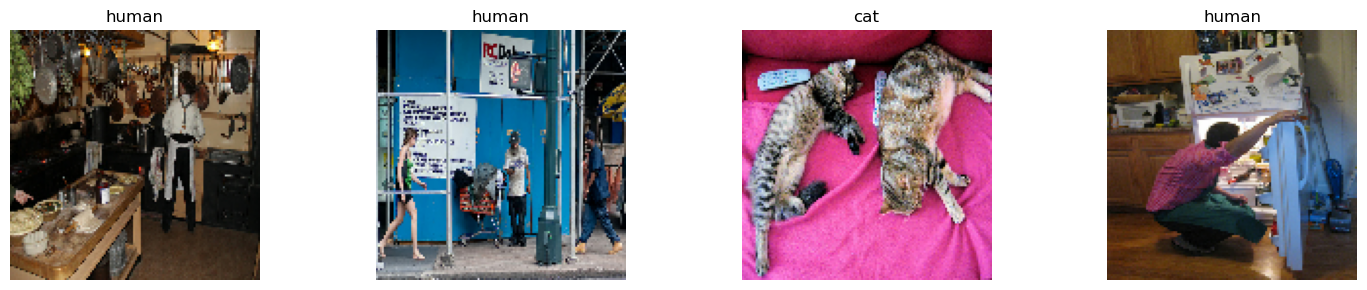

2025-06-25 09:40:52.855290: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [25]:
from tensorflow.keras.utils import image_dataset_from_directory

ds_train = image_dataset_from_directory(
    'data/images',
    labels='inferred',
    label_mode='int',
    image_size=(128, 128),
    batch_size=32,
    shuffle=True
)

class_names = ds_train.class_names 

for images, labels in ds_train.take(1):
    num_images = images.shape[0]
    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"{class_names[labels[i]]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

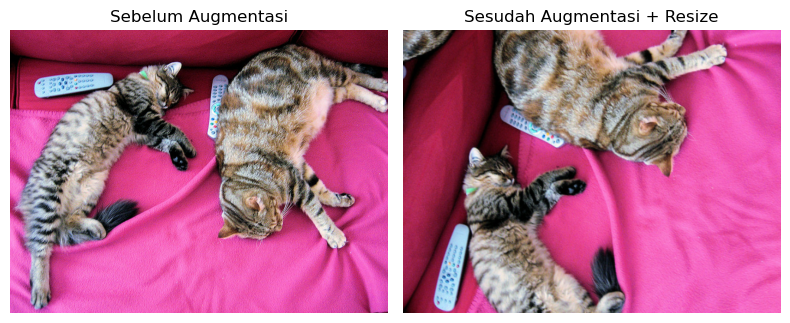

In [32]:
import tensorflow as tf
import matplotlib.pyplot as plt

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1)
])

img = tf.io.read_file('cat.jpg')
img = tf.image.decode_jpeg(img, channels=3)
img = tf.cast(img, tf.float32) / 255.0  

augmented_img = data_augmentation(img[None, ...])

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(img.numpy())
plt.title("Sebelum Augmentasi")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(augmented_img[0].numpy())
plt.title("Sesudah Augmentasi + Resize")
plt.axis('off')

plt.tight_layout()
plt.show()
